In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Load the Wine dataset
dataset = load_wine()
X = dataset.data
y = dataset.target

# Standardize features to have zero mean and unit variance
X_scaled = StandardScaler().fit_transform(X)

print("Dataset shape:", X_scaled.shape)
print("Number of features:", X_scaled.shape[1])
print("Number of classes:", len(np.unique(y)))

Dataset shape: (178, 13)
Number of features: 13
Number of classes: 3


In [2]:
# Center the standardized data
X_centered = X_scaled - np.mean(X_scaled, axis=0)

# Compute singular value decomposition
U, singular_values, Vt = np.linalg.svd(
    X_centered, full_matrices=False
)

# Calculate explained variance for each principal component
explained_variance = singular_values**2 / (X_centered.shape[0] - 1)
explained_variance_ratio = explained_variance / np.sum(explained_variance)

# Project the data onto the first two principal components
components = Vt[:2].T
X_pca = X_centered @ components

print("Reduced data shape:", X_pca.shape)
print("PC1 explained variance:", round(explained_variance_ratio[0], 4))
print("PC2 explained variance:", round(explained_variance_ratio[1], 4))
print(
    "Total variance explained:",
    round(explained_variance_ratio[:2].sum(), 4)
)

Reduced data shape: (178, 2)
PC1 explained variance: 0.362
PC2 explained variance: 0.1921
Total variance explained: 0.5541


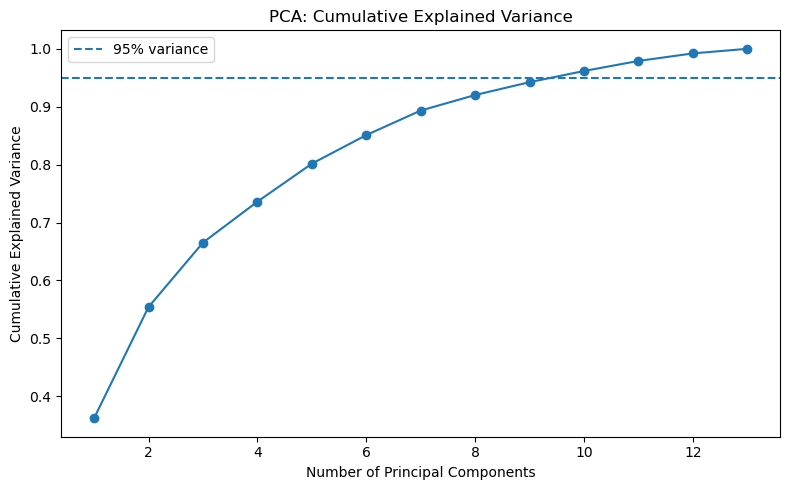

Components needed to explain at least 95% variance: 10


In [3]:
# Calculate cumulative explained variance
cumulative_variance = np.cumsum(explained_variance_ratio)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Cumulative Explained Variance")
plt.legend()
plt.tight_layout()

# Save the explained variance plot
plt.savefig(
    "../reports/figures/pca_explained_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Find the minimum number of components explaining at least 95% variance
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print("Components needed to explain at least 95% variance:", n_components_95)

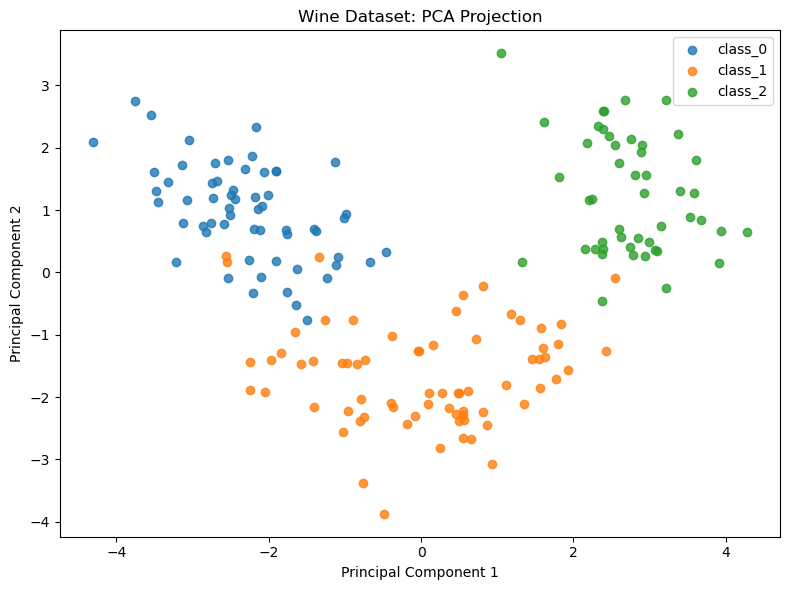

In [4]:
# Visualize the Wine dataset using the first two principal components
plt.figure(figsize=(8, 6))

for class_id, class_name in enumerate(dataset.target_names):
    mask = y == class_id
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=class_name,
        alpha=0.8
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wine Dataset: PCA Projection")
plt.legend()
plt.tight_layout()

# Save the PCA projection plot
plt.savefig(
    "../reports/figures/pca_projection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
from sklearn.decomposition import PCA

# Fit scikit-learn PCA using the standardized dataset
pca = PCA(n_components=2)
X_pca_sklearn = pca.fit_transform(X_scaled)

# Compare explained variance ratios
comparison = pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "From Scratch": explained_variance_ratio[:2],
    "scikit-learn": pca.explained_variance_ratio_
})

comparison

,Component,From Scratch,scikit-learn
0,PC1,0.361988,0.361988
1,PC2,0.192075,0.192075


In [6]:
# Compare the absolute correlations of corresponding PCA projections
correlations = [
    abs(np.corrcoef(X_pca[:, i], X_pca_sklearn[:, i])[0, 1])
    for i in range(2)
]

print("Absolute component correlations:", np.round(correlations, 6))

print(
    "Maximum explained-variance difference:",
    np.max(
        np.abs(
            explained_variance_ratio[:2]
            - pca.explained_variance_ratio_
        )
    )
)

Absolute component correlations: [1. 1.]
Maximum explained-variance difference: 4.996003610813204e-16


In [7]:
# Save the PCA projections and class labels
pca_results = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Class": dataset.target_names[y]
})

pca_results.to_csv("../reports/pca_results.csv", index=False)

# Save explained variance information for all principal components
variance_results = pd.DataFrame({
    "Component": [
        f"PC{i + 1}" for i in range(len(explained_variance_ratio))
    ],
    "Explained Variance Ratio": explained_variance_ratio,
    "Cumulative Explained Variance": cumulative_variance
})

variance_results.to_csv(
    "../reports/pca_explained_variance.csv",
    index=False
)

print("PCA results saved successfully.")

PCA results saved successfully.
